# Modelos de clasificación para detección temprana de fraude en entidades bancarias
## Notebook 03 — Random Forest

Sigue la estructura del código de clase *Ingeniería de variables + Random Forest*, a partir de la base de modelamiento construida en el **Notebook 01**:

1. **Metodología 1:** *fit train → predict test* (50% / 50%)
2. **Metodología 2:** *fit test → predict train* (se invierten los papeles) → permite medir la **estabilidad**
3. **Entrenamiento completo sin balanceo** de clases
4. **Entrenamiento completo con balanceo** (SMOTE + undersampling)
5. **Predicciones para Kaggle** (archivo csv)


**Random Forest** combina muchos árboles de decisión entrenados sobre muestras *bootstrap* y, en cada división, sobre un subconjunto aleatorio de variables. El voto (promedio de probabilidades) de los árboles **reduce la varianza** de un árbol individual.

Hiperparámetros de la grilla de clase: `n_estimators` (número de árboles), `max_depth` (profundidad máxima) y `min_samples_leaf` (mínimo de observaciones por hoja), que controlan la complejidad y el sobreajuste.


### Ajustes técnicos respecto al código de clase (y por qué)
| Código de clase | Este notebook | Motivo |
|---|---|---|
| `make_scorer(roc_auc_score)` y `predict()` (0/1) | `scoring="roc_auc"` y `predict_proba()` | La AUC mide qué tan bien el modelo **ordena** a los clientes por riesgo; con 0/1 la curva ROC tiene un solo punto y la AUC cae fuertemente (se demuestra abajo). Kaggle evalúa la AUC, así que se suben **probabilidades**. |
| `MinMaxScaler().fit_transform(X_test)` | Escalado dentro de un `Pipeline` | El escalado se aprende **solo con entrenamiento** y se aplica igual a test (evita fuga de información). |
| Balanceo de toda la base antes del `GridSearchCV` | Balanceo **dentro** del `Pipeline` | Así los folds de validación conservan la proporción real de fraude (6%) y la AUC de validación no se infla con datos sintéticos. |

## 0. Librerías y configuración

### Modo de ejecución
La variable `MODO` (en la celda siguiente) controla cuánto se busca:

| | `"rapido"` | `"completo"` | `"todos"` |
|---|---|---|---|
| Datos para la búsqueda (`FRAC_BUSQUEDA`) | 20% | 40% | **100%** |
| Combinaciones probadas (`N_ITER`) | 15 | 30 | 15 |
| `max_depth` | 5 a 15 | 12 a 25 y sin límite (`None`) | 12 a 25 y sin límite (`None`) |
| Tiempo aproximado | ~20 min | 1–2 horas | 2–3 horas |

Para la versión final: cambiar `MODO = "completo"` y ejecutar todo (*Run → Run All Cells*). Si la AUC de Test sube pero la **brecha Train-Test** pasa de ~0.02, el modelo empieza a sobreajustar y conviene subir `min_samples_leaf`.

In [1]:
import os, sys, json, time, pickle
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier

SEMILLA = 20042021
N_JOBS = 4             # procesos en paralelo; con -1 Docker se queda sin memoria al usar SMOTE

# MODO = "rapido"   -> 20% de los datos para la búsqueda, 15 combinaciones (~20 min en total)
# MODO = "completo" -> 40% de los datos, 30 combinaciones y árboles más profundos (puede tardar 1-2 horas)
# MODO = "todos"    -> 100% de los datos para la búsqueda, 15 combinaciones, grilla de "completo" (2-3 horas)
MODO = "todos"

FRAC_BUSQUEDA = {"rapido": 0.20, "completo": 0.40, "todos": 1.0}[MODO]   # fracción (estratificada) de los datos para buscar hiperparámetros
N_ITER = {"rapido": 15, "completo": 30, "todos": 15}[MODO]               # combinaciones de hiperparámetros que prueba RandomizedSearchCV
print(f"Modo {MODO}: búsqueda con {100*FRAC_BUSQUEDA:.0f}% de los datos y {N_ITER} combinaciones")

Modo todos: búsqueda con 100% de los datos y 15 combinaciones


In [2]:
if "google.colab" in sys.modules:
    DATA_DIR, ART_DIR = "/content/data/", "/content/artefactos/"
elif "DATABRICKS_RUNTIME_VERSION" in os.environ:
    DATA_DIR, ART_DIR = "/Volumes/main/default/fraude/", "/Volumes/main/default/fraude/artefactos/"
else:
    # Docker / local: busca la carpeta data/ (con train.csv) aquí o en las carpetas de arriba
    carpeta = os.path.abspath(".")
    while not os.path.exists(os.path.join(carpeta, "data", "train.csv")) and carpeta != os.path.dirname(carpeta):
        carpeta = os.path.dirname(carpeta)
    DATA_DIR = os.path.join(carpeta, "data", "")
    ART_DIR = "./artefactos/"
SUB_DIR = "./submissions/"
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)
DATA_DIR

'/work/data/'

## 1. Base de modelamiento (Notebook 01)

In [3]:
base_modelo = pd.read_parquet(ART_DIR + "base_modelo_train.parquet")
base_modelo_prueba = pd.read_parquet(ART_DIR + "base_modelo_test.parquet")

covariables = [x for x in base_modelo.columns if x not in ["Fraude"]]
X = base_modelo.get(covariables).copy()
y = base_modelo["Fraude"].copy()
X_prueba = base_modelo_prueba.get(covariables).copy()

print("Entrenamiento:", X.shape, "| Test Kaggle:", X_prueba.shape)
print(f"Tasa de fraude: {100*y.mean():.2f}%")
print("Covariables:", covariables)

Entrenamiento: (848548, 22) | Test Kaggle: (200027, 22)
Tasa de fraude: 5.99%
Covariables: ['Num_Tarjetas', 'Balance_Tj', 'Total_Transac', 'Trans_Int', 'Estado_LB', 'Genero_LB', 'Tipo_Tarjeta_LB', 'Balance_Tj_2', 'Total_Transac_2', 'Num_Tarjetas_2', 'Num_Tarjetas_Balance_Tj', 'Num_Tarjetas_Total_Transac', 'Balance_Tj_Total_Transac', 'Num_Tarjetas_coc_Balance_Tj', 'Balance_Tj_coc_Num_Tarjetas', 'Total_Transac_coc_Num_Tarjetas', 'Genero_Tipo_Tarjeta=Female_Visa', 'Genero_Tipo_Tarjeta=Male_MasterCard', 'Genero_Tipo_Tarjeta=Female_Discover', 'Balance_Tj_x_Genero=Male', 'Num_Tarjetas_x_Genero=Male', 'Balance_Tj_x_Tipo_Tarjeta=MasterCard']


## 2. Funciones de apoyo
Para reducir el tiempo de entrenamiento (más de 400.000 registros), `grilla_auc` hace la búsqueda en dos pasos:
1. **Búsqueda de hiperparámetros** con `RandomizedSearchCV` (`N_ITER` combinaciones al azar) sobre una **submuestra estratificada** del `FRAC_BUSQUEDA` de los datos, con la misma validación cruzada `StratifiedKFold`.
2. **Entrenamiento final**: un modelo nuevo con los mejores hiperparámetros se entrena con el **100%** de los datos recibidos.

Por eso la *AUC de validación cruzada* se calcula sobre la submuestra, mientras que las AUC de train/test y las predicciones usan el modelo entrenado con todos los datos.

In [4]:
def crear_modelo(balanceo=False):
    # Pipeline: escalado MinMax (como en clase) -> [balanceo] -> modelo
    pasos = [("escalado", MinMaxScaler())]
    if balanceo:
        # Mismo esquema de clase: SMOTE sobre la clase minoritaria + undersampling de la mayoritaria
        pasos += [("over", SMOTE(sampling_strategy="not majority", random_state=SEMILLA)),
                  ("under", RandomUnderSampler(sampling_strategy="not minority", replacement=True, random_state=SEMILLA))]
    pasos += [("modelo", RandomForestClassifier(n_jobs=1, random_state=SEMILLA))]
    return ImbPipeline(pasos) if balanceo else Pipeline(pasos)

# Grilla ajustada: árboles algo más profundos que [2, 3, 5] (con min_samples_leaf para controlar el sobreajuste),
# max_features para decorrelacionar los árboles y max_samples para que cada árbol use solo parte de los datos (más rápido)
if MODO == "rapido":
    parametros = {'modelo__n_estimators': [100, 200, 300],
                  'modelo__max_depth': [5, 8, 10, 12, 15],
                  'modelo__min_samples_leaf': [15, 20, 30, 40, 60],
                  'modelo__max_features': ['sqrt', 0.3, 0.5],
                  'modelo__max_samples': [0.3, 0.5, 0.7]}
else:
    # En modo rápido el mejor max_depth fue casi siempre 15 (el tope), así que se amplía hacia arriba.
    # None = sin límite de profundidad; min_samples_leaf es lo que controla el sobreajuste.
    parametros = {'modelo__n_estimators': [200, 300, 500],
                  'modelo__max_depth': [12, 15, 20, 25, None],
                  'modelo__min_samples_leaf': [10, 20, 40, 60, 100],
                  'modelo__max_features': ['sqrt', 0.3, 0.5],
                  'modelo__max_samples': [0.3, 0.5, 0.7]}

def grilla_auc(X_fit, y_fit, balanceo=False, k=5, param=None):
    param = parametros if param is None else param
    # 1) Submuestra estratificada para la búsqueda de hiperparámetros
    if FRAC_BUSQUEDA < 1:
        X_sub, _, y_sub, _ = train_test_split(X_fit, y_fit, train_size=FRAC_BUSQUEDA, stratify=y_fit, random_state=SEMILLA)
    else:
        X_sub, y_sub = X_fit, y_fit   # modo "todos": la búsqueda usa el 100% de los datos
    busqueda = RandomizedSearchCV(estimator=crear_modelo(balanceo), param_distributions=param, n_iter=N_ITER,
                                  scoring="roc_auc", cv=StratifiedKFold(k, shuffle=True, random_state=SEMILLA),
                                  n_jobs=N_JOBS, return_train_score=True, random_state=SEMILLA, refit=False)
    t0 = time.time()
    busqueda.fit(X_sub, y_sub)
    t1 = time.time()
    # 2) Modelo nuevo con los mejores hiperparámetros, entrenado con el 100% de los datos
    final = crear_modelo(balanceo).set_params(**busqueda.best_params_, modelo__n_jobs=N_JOBS)
    final.fit(X_fit, y_fit)
    # Se guarda dentro del objeto de búsqueda para que el resto del notebook lo use igual que antes
    busqueda.best_estimator_, busqueda.refit = final, True
    i = busqueda.best_index_
    print(f"Mejores hiperparámetros: {busqueda.best_params_}")
    print(f"Búsqueda en {len(X_sub):,} registros ({100*FRAC_BUSQUEDA:.0f}%): {t1-t0:.0f} s | entrenamiento final en {len(X_fit):,} registros: {time.time()-t1:.0f} s")
    print(f"AUC validación cruzada ({k} folds, submuestra): {busqueda.cv_results_['mean_test_score'][i]:.4f} ± {busqueda.cv_results_['std_test_score'][i]:.4f}")
    return busqueda

def umbral_youden(y_true, proba):
    # Umbral que maximiza TPR - FPR (punto de la curva ROC más alejado de la diagonal)
    fpr, tpr, thr = roc_curve(y_true, proba)
    return thr[np.argmax(tpr - fpr)]

def predicciones(modelo, X_eval, y_eval, titulo="", umbral=None):
    proba = modelo.predict_proba(X_eval)[:, 1]
    auc_proba = roc_auc_score(y_eval, proba)
    auc_01 = roc_auc_score(y_eval, (proba >= 0.5).astype(int))
    if umbral is None:
        umbral = umbral_youden(y_eval, proba)
    yhat = (proba >= umbral).astype(int)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(pd.DataFrame(confusion_matrix(y_eval, yhat)), annot=True, fmt=",.0f", cmap="Blues", ax=ax[0], cbar=False)
    ax[0].set_title(f"Matriz de confusión (umbral = {umbral:.3f})")
    ax[0].set_xlabel("Valores predichos"); ax[0].set_ylabel("Valores observados")
    fpr, tpr, _ = roc_curve(y_eval, proba)
    ax[1].plot(fpr, tpr, color="#C44E52", lw=2, label=f"Probabilidades: AUC = {auc_proba:.4f}")
    fpr2, tpr2, _ = roc_curve(y_eval, (proba >= 0.5).astype(int))
    ax[1].plot(fpr2, tpr2, color="gray", lw=1.5, ls=":", marker="o", label=f"Solo 0/1 (predict): AUC = {auc_01:.4f}")
    ax[1].plot([0, 1], [0, 1], color="lightgray", ls="--")
    ax[1].set_xlabel("FPR (falsas alarmas)"); ax[1].set_ylabel("TPR (recall / sensibilidad)")
    ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()

    res = {"AUC": auc_proba, "AUC_0_1": auc_01, "umbral": umbral,
           "Recall": recall_score(y_eval, yhat), "Precision": precision_score(y_eval, yhat), "F1": f1_score(y_eval, yhat)}
    print(f"AUC (probabilidades) = {auc_proba:.4f} | AUC (0/1 con predict) = {auc_01:.4f}")
    print(f"Con umbral {umbral:.3f}: Recall = {res['Recall']:.3f} | Precision = {res['Precision']:.3f} | F1 = {res['F1']:.3f}")
    return res

## 3. Muestras de entrenamiento y test (50% / 50%, estratificado)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=19052023, stratify=y)
print("Train:", X_train.shape, f"fraude {100*y_train.mean():.2f}%")
print("Test: ", X_test.shape, f"fraude {100*y_test.mean():.2f}%")

Train: (424274, 22) fraude 5.99%
Test:  (424274, 22) fraude 5.99%


# Random Forest sin balanceo de clases
## Metodología 1: *fit train → predict test*

In [6]:
%%time
grilla1 = grilla_auc(X_train, y_train)

Mejores hiperparámetros: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 40, 'modelo__max_samples': 0.7, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 15}
Búsqueda en 424,274 registros (100%): 2518 s | entrenamiento final en 424,274 registros: 33 s
AUC validación cruzada (5 folds, submuestra): 0.9318 ± 0.0019
CPU times: user 2min 9s, sys: 0 ns, total: 2min 9s
Wall time: 42min 31s


### Predicción Train

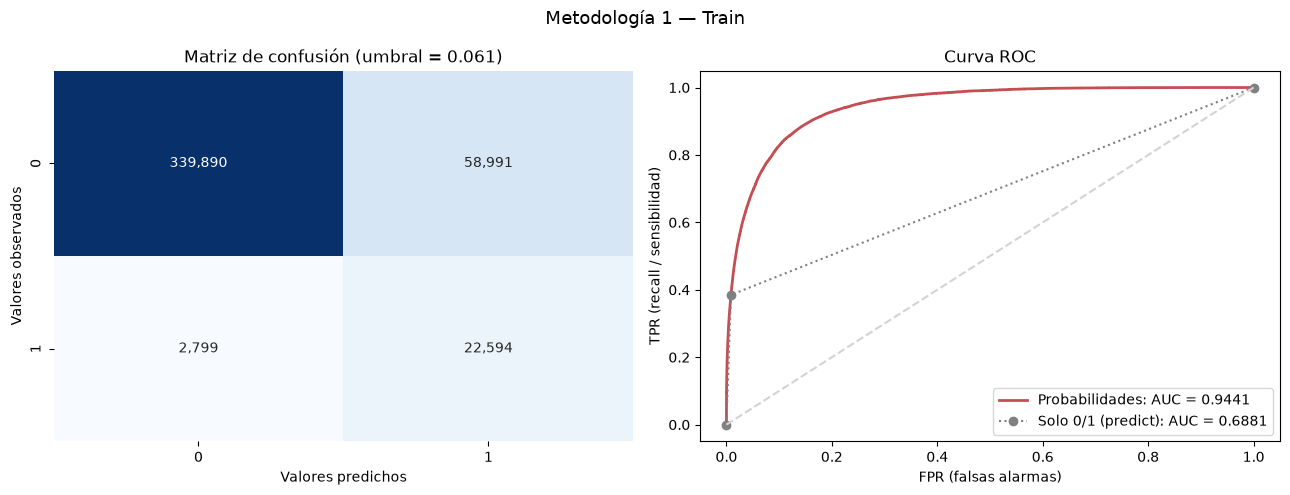

AUC (probabilidades) = 0.9441 | AUC (0/1 con predict) = 0.6881
Con umbral 0.061: Recall = 0.890 | Precision = 0.277 | F1 = 0.422


In [7]:
res1_train = predicciones(grilla1, X_train, y_train, "Metodología 1 — Train")

### Predicción Test

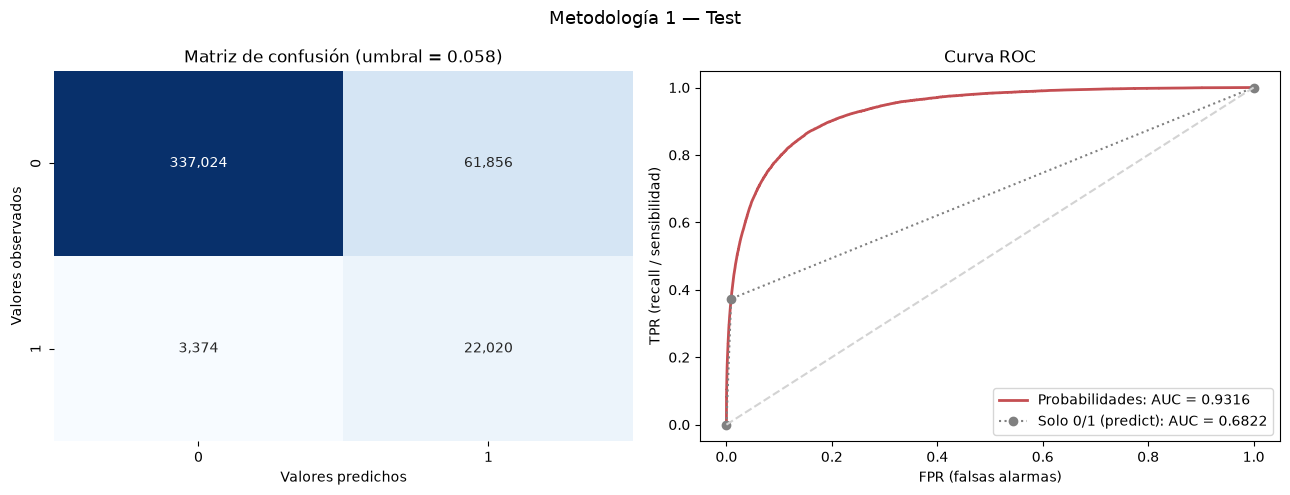

AUC (probabilidades) = 0.9316 | AUC (0/1 con predict) = 0.6822
Con umbral 0.058: Recall = 0.867 | Precision = 0.263 | F1 = 0.403


In [8]:
res1_test = predicciones(grilla1, X_test, y_test, "Metodología 1 — Test")

## Metodología 2: *fit test → predict train*

In [9]:
%%time
grilla2 = grilla_auc(X_test, y_test)

Mejores hiperparámetros: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 40, 'modelo__max_samples': 0.7, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 15}
Búsqueda en 424,274 registros (100%): 2580 s | entrenamiento final en 424,274 registros: 31 s
AUC validación cruzada (5 folds, submuestra): 0.9313 ± 0.0013
CPU times: user 2min 6s, sys: 0 ns, total: 2min 6s
Wall time: 43min 30s


### Predicción Train (la mitad con la que se entrenó: X_test)

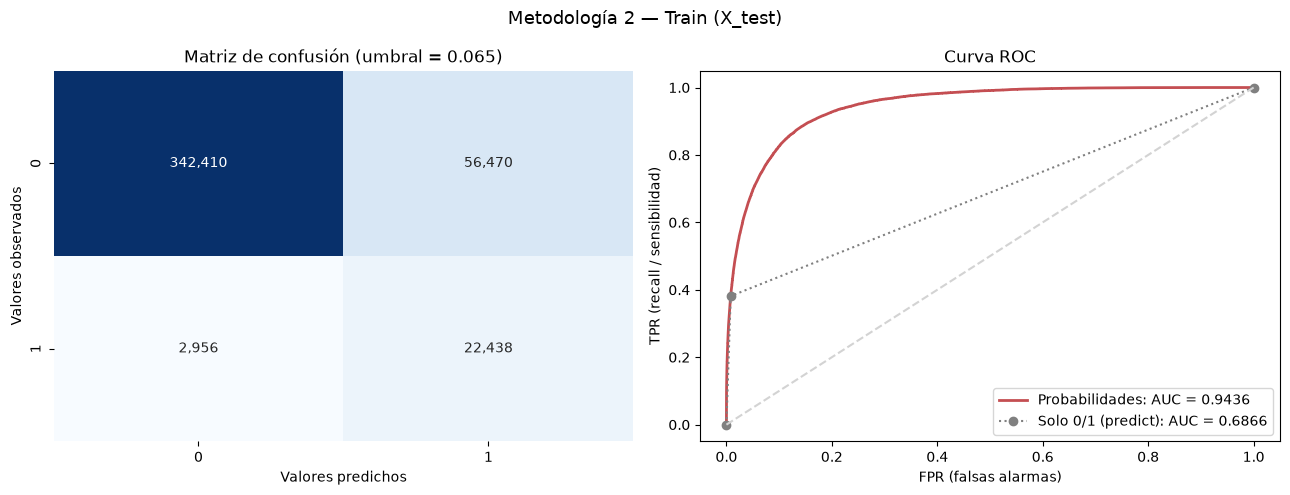

AUC (probabilidades) = 0.9436 | AUC (0/1 con predict) = 0.6866
Con umbral 0.065: Recall = 0.884 | Precision = 0.284 | F1 = 0.430


In [10]:
res2_train = predicciones(grilla2, X_test, y_test, "Metodología 2 — Train (X_test)")

### Predicción Test (la mitad no vista: X_train)

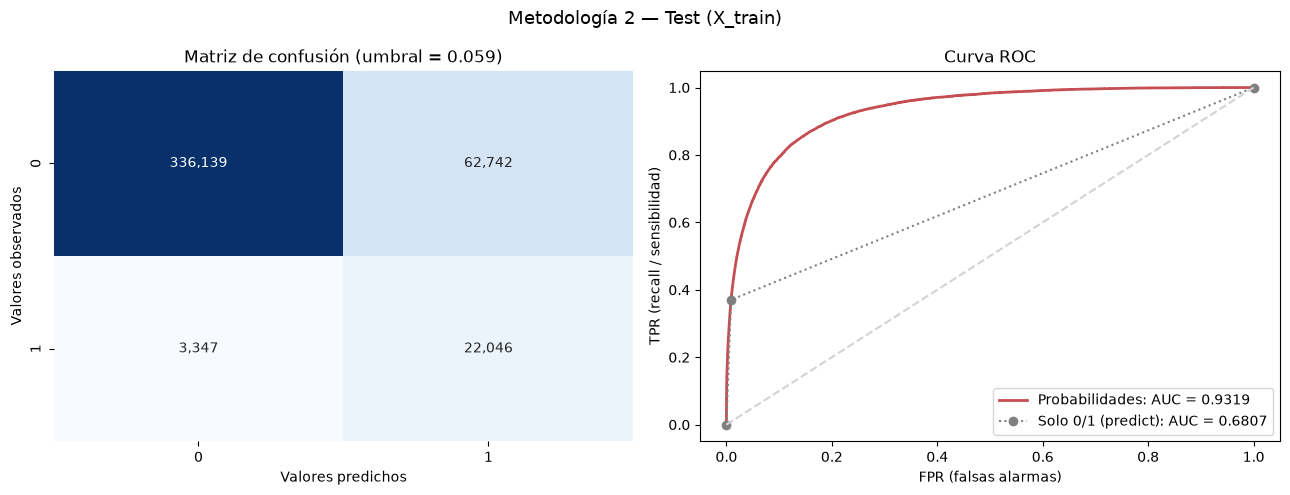

AUC (probabilidades) = 0.9319 | AUC (0/1 con predict) = 0.6807
Con umbral 0.059: Recall = 0.868 | Precision = 0.260 | F1 = 0.400


In [11]:
res2_test = predicciones(grilla2, X_train, y_train, "Metodología 2 — Test (X_train)")

## Estabilidad del modelo
Un modelo **estable** debe tener una AUC similar: (a) entre entrenamiento y prueba (sin sobreajuste), (b) entre las dos metodologías (no depende de qué mitad de los datos se use) y (c) entre los folds de la validación cruzada (desviación estándar pequeña).

In [12]:
def resumen(grilla, r_train, r_test, nombre):
    i = grilla.best_index_
    return {"Metodología": nombre, "Hiperparámetros": str({k.replace("modelo__",""): v for k, v in grilla.best_params_.items()}),
            "AUC CV (media)": grilla.cv_results_["mean_test_score"][i], "AUC CV (desv.)": grilla.cv_results_["std_test_score"][i],
            "AUC Train": r_train["AUC"], "AUC Test": r_test["AUC"], "Brecha Train-Test": r_train["AUC"] - r_test["AUC"],
            "AUC Test con 0/1": r_test["AUC_0_1"]}

estabilidad = pd.DataFrame([resumen(grilla1, res1_train, res1_test, "1: fit train → predict test"),
                            resumen(grilla2, res2_train, res2_test, "2: fit test → predict train")])
estabilidad.round(4)

,Metodología,Hiperparámetros,AUC CV (media),AUC CV (desv.),AUC Train,AUC Test,Brecha Train-Test,AUC Test con 0/1
0,1: fit train → predict test,"{'n_estimators': 300, 'min_samples_leaf': 40, ...",0.9318,0.0019,0.9441,0.9316,0.0125,0.6822
1,2: fit test → predict train,"{'n_estimators': 300, 'min_samples_leaf': 40, ...",0.9313,0.0013,0.9436,0.9319,0.0116,0.6807


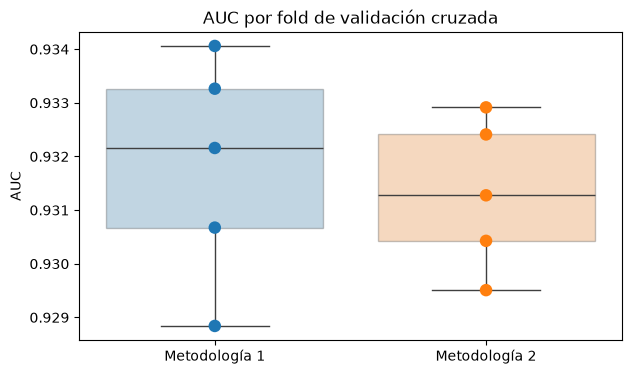

In [13]:
# Distribución de la AUC de validación en los 5 folds para la mejor configuración de cada metodología
folds = pd.DataFrame({f"Metodología {m}": [g.cv_results_[f"split{k}_test_score"][g.best_index_] for k in range(5)]
                      for m, g in [(1, grilla1), (2, grilla2)]})
plt.figure(figsize=(7,4))
sns.stripplot(data=folds, size=9, jitter=False); sns.boxplot(data=folds, boxprops={"alpha":0.3})
plt.title("AUC por fold de validación cruzada"); plt.ylabel("AUC"); plt.show()

# 1. Entrenamiento completo sin balanceo
Se buscan los hiperparámetros con 3 folds (como en clase) sobre la submuestra y el modelo final se entrena con **toda** la base de entrenamiento.

In [14]:
%%time
Random_BE = grilla_auc(X, y, balanceo=False, k=3)

Mejores hiperparámetros: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 40, 'modelo__max_samples': 0.7, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 15}
Búsqueda en 848,548 registros (100%): 2731 s | entrenamiento final en 848,548 registros: 71 s
AUC validación cruzada (3 folds, submuestra): 0.9322 ± 0.0017
CPU times: user 4min 39s, sys: 1.79 s, total: 4min 41s
Wall time: 46min 41s


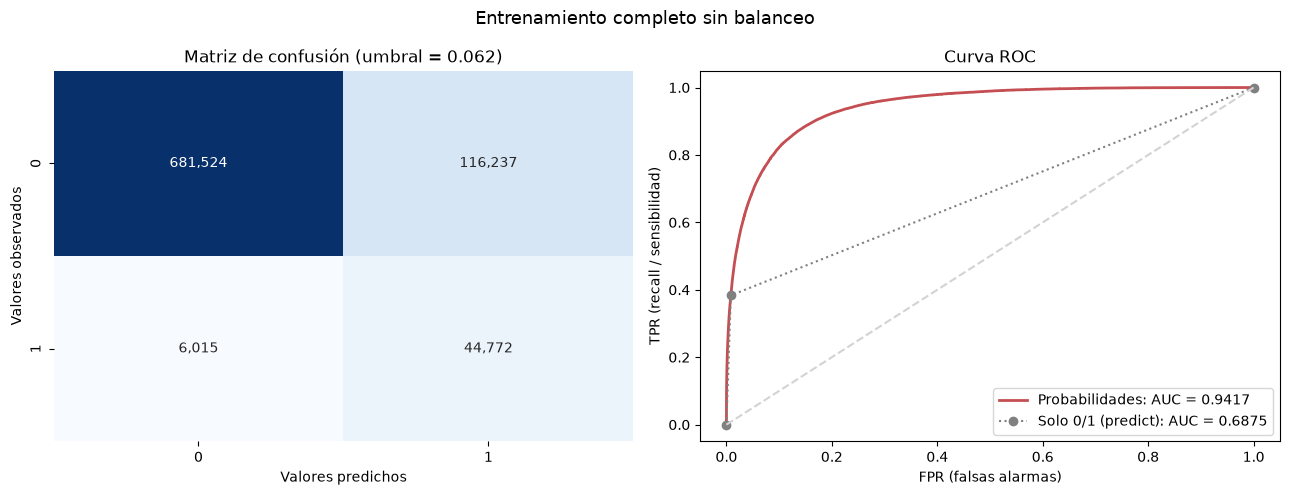

AUC (probabilidades) = 0.9417 | AUC (0/1 con predict) = 0.6875
Con umbral 0.062: Recall = 0.882 | Precision = 0.278 | F1 = 0.423


In [15]:
res_SB = predicciones(Random_BE, X, y, "Entrenamiento completo sin balanceo")

# 2. Entrenamiento completo con balanceo de clases
Se aplica el esquema de clase (`SMOTE` + `RandomUnderSampler`) **dentro de cada fold**. Primero se verifica el efecto del balanceo sobre la proporción de clases:

In [16]:
X_udr, y_udr = ImbPipeline([("over", SMOTE(sampling_strategy="not majority", random_state=SEMILLA)),
                            ("under", RandomUnderSampler(sampling_strategy="not minority", replacement=True, random_state=SEMILLA))]
                          ).fit_resample(MinMaxScaler().fit_transform(X), y)
print(f"Antes:   {X.shape[0]:,} registros | fraude {100*np.mean(y):.2f}%")
print(f"Después: {X_udr.shape[0]:,} registros | fraude {100*np.mean(y_udr):.2f}%")
del X_udr, y_udr

Antes:   848,548 registros | fraude 5.99%
Después: 1,595,522 registros | fraude 50.00%


In [17]:
%%time
Random_BE_Balanced = grilla_auc(X, y, balanceo=True, k=3)

Mejores hiperparámetros: {'modelo__n_estimators': 500, 'modelo__min_samples_leaf': 60, 'modelo__max_samples': 0.3, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 15}
Búsqueda en 848,548 registros (100%): 6631 s | entrenamiento final en 848,548 registros: 151 s
AUC validación cruzada (3 folds, submuestra): 0.9288 ± 0.0015
CPU times: user 9min 53s, sys: 10.3 s, total: 10min 4s
Wall time: 1h 53min 1s


La evaluación se hace sobre los datos **reales** (sin datos sintéticos):

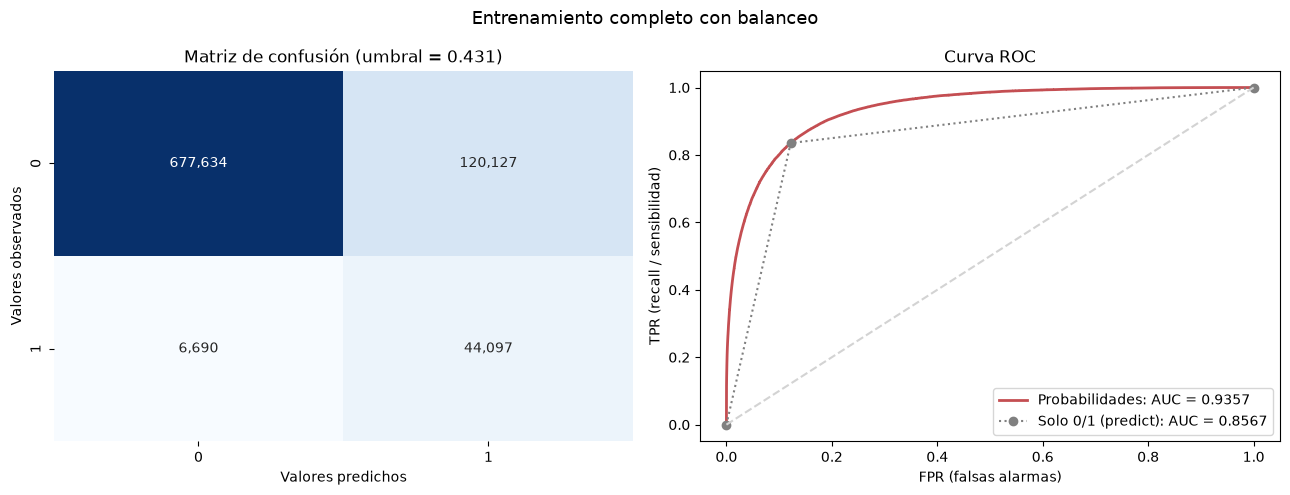

AUC (probabilidades) = 0.9357 | AUC (0/1 con predict) = 0.8567
Con umbral 0.431: Recall = 0.868 | Precision = 0.269 | F1 = 0.410


In [18]:
res_B = predicciones(Random_BE_Balanced, X, y, "Entrenamiento completo con balanceo")

## Comparación: sin balanceo vs con balanceo

In [19]:
comparacion = pd.DataFrame([
    {"Modelo": "Sin balanceo", "AUC CV (media)": Random_BE.best_score_, "AUC CV (desv.)": Random_BE.cv_results_["std_test_score"][Random_BE.best_index_], **{k: v for k, v in res_SB.items()}},
    {"Modelo": "Con balanceo", "AUC CV (media)": Random_BE_Balanced.best_score_, "AUC CV (desv.)": Random_BE_Balanced.cv_results_["std_test_score"][Random_BE_Balanced.best_index_], **{k: v for k, v in res_B.items()}},
]).set_index("Modelo")
comparacion.round(4)

,AUC CV (media),AUC CV (desv.),AUC,AUC_0_1,umbral,Recall,Precision,F1
Modelo,,,,,,,,
Sin balanceo,0.9322,0.0017,0.9417,0.6875,0.0622,0.8816,0.2781,0.4228
Con balanceo,0.9288,0.0015,0.9357,0.8567,0.4311,0.8683,0.2685,0.4102


## Importancia de variables del modelo final

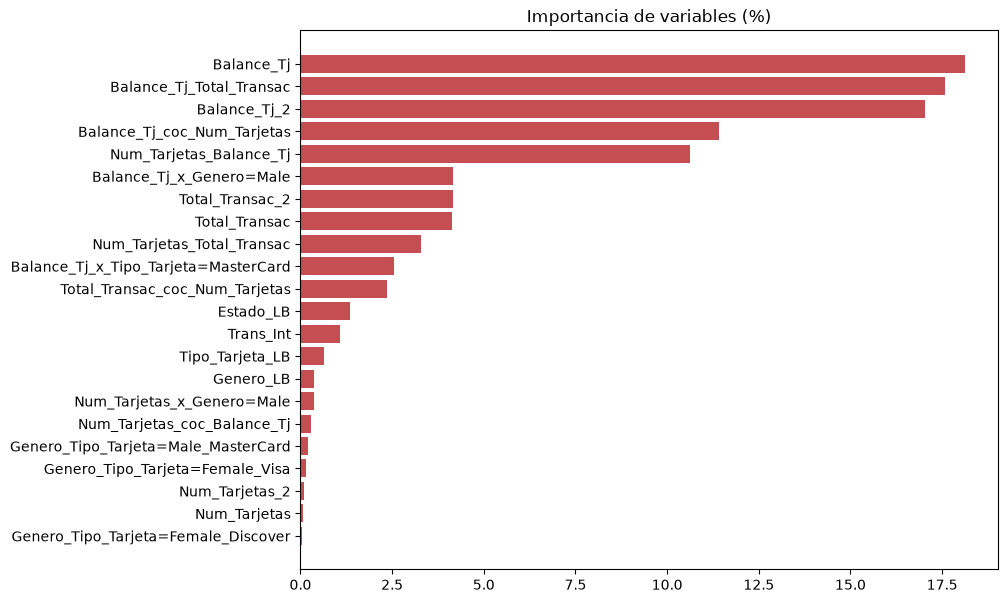

,Variable,Importancia
0,Balance_Tj,18.12
1,Balance_Tj_Total_Transac,17.58
2,Balance_Tj_2,17.03
3,Balance_Tj_coc_Num_Tarjetas,11.41
4,Num_Tarjetas_Balance_Tj,10.62
5,Balance_Tj_x_Genero=Male,4.15
6,Total_Transac_2,4.15
7,Total_Transac,4.14
8,Num_Tarjetas_Total_Transac,3.28
9,Balance_Tj_x_Tipo_Tarjeta=MasterCard,2.55


In [20]:
modelo_final = Random_BE.best_estimator_.named_steps["modelo"]
imp = pd.DataFrame({"Variable": covariables, "Importancia": 100 * modelo_final.feature_importances_ / modelo_final.feature_importances_.sum()})
imp = imp.sort_values("Importancia", ascending=False).reset_index(drop=True)
plt.figure(figsize=(9,7))
plt.barh(imp["Variable"][::-1], imp["Importancia"][::-1], color="#C44E52")
plt.title("Importancia de variables (%)"); plt.show()
imp.round(2)

# Análisis de sensibilidad: efecto del orden del `ID`
En el Notebook 01 se encontró que, dentro de cada grupo (Estado, Género, Tipo de tarjeta), el fraude se concentra en los **últimos IDs**. Se construye la variable `pos_ID` = posición relativa (0 a 1) del cliente dentro de su grupo, calculada sobre train y test juntos (los IDs de test están intercalados con los de train), y se mide cuánto cambia la AUC.

> ⚠️ Esta variable es un **artefacto de construcción del archivo** (fuga de información), no un comportamiento del cliente. Se reporta por transparencia y como **riesgo del modelo**; no estaría disponible en un sistema real de prevención de fraude.

In [21]:
grupo = ["Estado", "Genero", "Tipo_Tarjeta"]
crudo = pd.concat([pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"] + grupo),
                   pd.read_csv(DATA_DIR + "test.csv",  sep=";", usecols=["ID"] + grupo)])
crudo["pos_ID"] = crudo.groupby(grupo)["ID"].rank(pct=True)
pos = crudo.set_index("ID")["pos_ID"]

ids_train = pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"])["ID"]
X_id = X.copy();               X_id["pos_ID"] = pos.loc[ids_train].values
X_prueba_id = X_prueba.copy(); X_prueba_id["pos_ID"] = pos.loc[base_modelo_prueba["ID"]].values

In [22]:
%%time
mejor_balanceo = comparacion["AUC CV (media)"].idxmax() == "Con balanceo"
mejores_params = (Random_BE_Balanced if mejor_balanceo else Random_BE).best_params_
# Mismos hiperparámetros y misma submuestra (misma semilla), así la AUC CV es comparable
grilla_id = grilla_auc(X_id, y, balanceo=mejor_balanceo, k=3, param={k: [v] for k, v in mejores_params.items()})
print(f"AUC CV sin pos_ID: {max(comparacion['AUC CV (media)']):.4f}")
print(f"AUC CV con pos_ID: {grilla_id.best_score_:.4f}")

Mejores hiperparámetros: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 40, 'modelo__max_samples': 0.7, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 15}
Búsqueda en 848,548 registros (100%): 173 s | entrenamiento final en 848,548 registros: 74 s
AUC validación cruzada (3 folds, submuestra): 0.9559 ± 0.0006
AUC CV sin pos_ID: 0.9322
AUC CV con pos_ID: 0.9559
CPU times: user 4min 51s, sys: 1.15 s, total: 4min 52s
Wall time: 4min 6s


# Predicciones nuevos datos (Kaggle)
Formato del `sample_submission.csv`: columnas `ID` y `Fraude`, separadas por coma. En `Fraude` se sube la **probabilidad** de fraude.

In [23]:
def guardar_submission(proba, nombre):
    evaluacion = pd.DataFrame({"ID": base_modelo_prueba["ID"].values, "Fraude": proba})
    evaluacion.to_csv(SUB_DIR + nombre, index=False, sep=",")
    print(f"{nombre}: {len(evaluacion):,} filas | probabilidad media = {evaluacion['Fraude'].mean():.4f}")
    return evaluacion

sub_SB = guardar_submission(Random_BE.predict_proba(X_prueba)[:, 1],                  "submission_rforest_no_balanceo.csv")
sub_B  = guardar_submission(Random_BE_Balanced.predict_proba(X_prueba)[:, 1],         "submission_rforest_balanceo.csv")
sub_ID = guardar_submission(grilla_id.predict_proba(X_prueba_id)[:, 1],               "submission_rforest_con_posID.csv")
sub_SB.head()

submission_rforest_no_balanceo.csv: 200,027 filas | probabilidad media = 0.0597
submission_rforest_balanceo.csv: 200,027 filas | probabilidad media = 0.2105
submission_rforest_con_posID.csv: 200,027 filas | probabilidad media = 0.0598


,ID,Fraude
0,9,0.013922
1,11,0.003936
2,19,0.007195
3,20,0.012066
4,22,0.003951


In [24]:
# Validación del formato contra la plantilla de Kaggle
plantilla = pd.read_csv(DATA_DIR + "sample_submission.csv")
for s in [sub_SB, sub_B, sub_ID]:
    assert list(s.columns) == list(plantilla.columns) and (s["ID"].values == plantilla["ID"].values).all()
    assert s["Fraude"].between(0, 1).all() and s["Fraude"].notnull().all()
print("✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv")

✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv


## Guardar modelos y resultados (para el Notebook 06 de comparación)

In [25]:
with open(ART_DIR + "modelo_rforest_no_balanceo.pkl", "wb") as f: pickle.dump(Random_BE.best_estimator_, f)
with open(ART_DIR + "modelo_rforest_balanceo.pkl", "wb") as f:    pickle.dump(Random_BE_Balanced.best_estimator_, f)

resultados = {
    "modelo": "Random Forest",
    "estabilidad": estabilidad.to_dict(orient="records"),
    "folds_cv": folds.to_dict(orient="list"),
    "completo": comparacion.reset_index().to_dict(orient="records"),
    "auc_cv_con_posID": grilla_id.best_score_,
    "balanceo_elegido": bool(mejor_balanceo),
}
with open(ART_DIR + "resultados_rforest.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print(sorted(os.listdir(ART_DIR)))

['base_modelo_test.parquet', 'base_modelo_train.parquet', 'modelo_ensamble_balanceo.pkl', 'modelo_ensamble_no_balanceo.pkl', 'modelo_logistica_balanceo.pkl', 'modelo_logistica_no_balanceo.pkl', 'modelo_rforest_balanceo.pkl', 'modelo_rforest_no_balanceo.pkl', 'modelo_xgboost_balanceo.pkl', 'modelo_xgboost_no_balanceo.pkl', 'receta_variables.json', 'resultados_ensamble.json', 'resultados_logistica.json', 'resultados_rforest.json', 'resultados_xgboost.json']


## Conclusiones

_(se completa tras revisar los resultados)_